In [7]:
import pandas as pd

df = pd.read_csv("/content/student-mat.csv", sep=";")
print(df.shape)
df.head()

(395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


# What explains students' final marks?
Data: UCI Student Performance data, maths class, 395 students. Target: the final mark G3 (out of 20). Method: linear regression.

In [8]:
print("Empty cells:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print()

print("Final mark G3 (out of 20):")
print(df["G3"].describe().round(1))
print()
print("Students with a final mark of 0:", (df["G3"] == 0).sum())
print()

# correlation: a number from -1 to 1 showing how closely each column moves with G3
print("Correlation with the final mark G3:")
print(df.corr(numeric_only=True)["G3"].drop("G3").sort_values().round(2))

Empty cells: 0
Duplicate rows: 0

Final mark G3 (out of 20):
count    395.0
mean      10.4
std        4.6
min        0.0
25%        8.0
50%       11.0
75%       14.0
max       20.0
Name: G3, dtype: float64

Students with a final mark of 0: 38

Correlation with the final mark G3:
failures     -0.36
age          -0.16
goout        -0.13
traveltime   -0.12
health       -0.06
Dalc         -0.05
Walc         -0.05
freetime      0.01
absences      0.03
famrel        0.05
studytime     0.10
Fedu          0.15
Medu          0.22
G1            0.80
G2            0.90
Name: G3, dtype: float64


## Cleaning
No empty cells and no duplicates. 38 students have a final mark of 0 and also 0 absences, which looks like students who left or never sat the final. I left them out, which leaves 357 students.

In [9]:
zero = df[df["G3"] == 0]
rest = df[df["G3"] > 0]

cols = ["G1", "G2", "absences", "failures", "studytime"]
print("Average values: students with G3 = 0 vs everyone else")
print(pd.DataFrame({"G3 = 0": zero[cols].mean(), "G3 > 0": rest[cols].mean()}).round(1))
print()
print("Of the", len(zero), "students with G3 = 0:")
print("  with absences = 0:", (zero["absences"] == 0).sum())
print("  with G2 = 0:", (zero["G2"] == 0).sum())
print()
print("Correlation between the three marks:")
print(df[["G1", "G2", "G3"]].corr().round(2))

Average values: students with G3 = 0 vs everyone else
           G3 = 0  G3 > 0
G1            7.5    11.3
G2            4.7    11.4
absences      0.0     6.3
failures      0.9     0.3
studytime     2.0     2.0

Of the 38 students with G3 = 0:
  with absences = 0: 38
  with G2 = 0: 13

Correlation between the three marks:
      G1    G2   G3
G1  1.00  0.85  0.8
G2  0.85  1.00  0.9
G3  0.80  0.90  1.0


## Model A: habits and background (no earlier marks)
R-squared 0.26. Clearly linked factors: schoolsup, failures, absences and goout. Extra school support goes with lower marks, probably because it goes to students who are already struggling.

In [10]:
import statsmodels.api as sm

# leave out the 38 students with G3 = 0 (all have absences = 0, so they look like non-completers)
d = df[df["G3"] > 0].copy()
print("Students used:", len(d))

# the factors we use (no earlier marks yet)
numeric = ["studytime", "failures", "absences", "age", "Medu", "Fedu",
           "traveltime", "goout", "freetime", "famrel", "health", "Dalc", "Walc"]
yesno = ["schoolsup", "famsup", "paid", "higher", "internet"]

X = pd.get_dummies(d[numeric + yesno], columns=yesno, drop_first=True).astype(float)
X = sm.add_constant(X)
y = d["G3"]

model_a = sm.OLS(y, X).fit()
print(model_a.summary())

Students used: 357
                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.260
Model:                            OLS   Adj. R-squared:                  0.220
Method:                 Least Squares   F-statistic:                     6.587
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           4.14e-14
Time:                        18:30:45   Log-Likelihood:                -870.72
No. Observations:                 357   AIC:                             1779.
Df Residuals:                     338   BIC:                             1853.
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const            15.3660   

## Model B: adds the earlier marks G1 and G2
R-squared 0.94. G2 does most of the work, and the other factors mostly stop mattering.

In [11]:
# Model B: the same factors plus the two earlier marks
XB = X.copy()
XB["G1"] = d["G1"]
XB["G2"] = d["G2"]
model_b = sm.OLS(y, XB).fit()

print("Model A (habits and background):     R-squared =", round(model_a.rsquared, 2), "| adjusted =", round(model_a.rsquared_adj, 2))
print("Model B (plus earlier marks G1, G2): R-squared =", round(model_b.rsquared, 2), "| adjusted =", round(model_b.rsquared_adj, 2))
print()

# factors that are clearly linked in Model B (p below 0.05)
p = model_b.pvalues.drop("const")
sig = p[p < 0.05].index
print("Clearly linked factors in Model B, with their coefficients:")
print(model_b.params[sig].round(2))

Model A (habits and background):     R-squared = 0.26 | adjusted = 0.22
Model B (plus earlier marks G1, G2): R-squared = 0.94 | adjusted = 0.94

Clearly linked factors in Model B, with their coefficients:
absences   -0.01
famrel      0.17
health     -0.07
G1          0.11
G2          0.87
dtype: float64


## Testing on students not used to fit the models
Typical error: 3.11 marks if we always guess the average, 2.74 with Model A, 0.83 with Model B.

Test students: 72
Error if we always guess the average mark: 3.11 marks
Model A error: 2.74 marks
Model B error: 0.83 marks


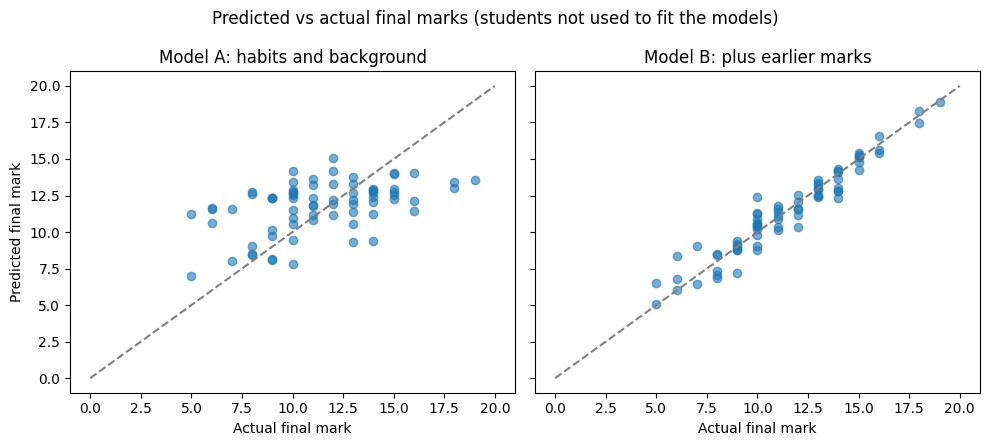

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt

XA = X.drop(columns="const")
XBn = XB.drop(columns="const")

# hold back 20% of students for testing
XA_tr, XA_te, y_tr, y_te = train_test_split(XA, y, test_size=0.2, random_state=42)
XB_tr, XB_te = XBn.loc[XA_tr.index], XBn.loc[XA_te.index]

def rmse(actual, pred):
    # typical size of the error, in marks
    return np.sqrt(((actual - pred) ** 2).mean())

pred_a = LinearRegression().fit(XA_tr, y_tr).predict(XA_te)
pred_b = LinearRegression().fit(XB_tr, y_tr).predict(XB_te)

print("Test students:", len(y_te))
print("Error if we always guess the average mark:", round(rmse(y_te, y_tr.mean()), 2), "marks")
print("Model A error:", round(rmse(y_te, pred_a), 2), "marks")
print("Model B error:", round(rmse(y_te, pred_b), 2), "marks")

# chart: predicted vs actual marks for the held-back students
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, pred, title in [(axes[0], pred_a, "Model A: habits and background"),
                        (axes[1], pred_b, "Model B: plus earlier marks")]:
    ax.scatter(y_te, pred, alpha=0.6)
    ax.plot([0, 20], [0, 20], color="grey", linestyle="--")   # dashed line = perfect prediction
    ax.set_title(title)
    ax.set_xlabel("Actual final mark")
axes[0].set_ylabel("Predicted final mark")
plt.suptitle("Predicted vs actual final marks (students not used to fit the models)")
plt.tight_layout()
plt.savefig("q_regression_predictions.png", dpi=150)
plt.show()